# Question B: comfort scoring (PMV)

IS4001 Smart Building Analytics project.

**What this notebook does**

1. Loads the clean 15-minute tables made by `cubems_prepare` for Floors 2-7.
2. Keeps office hours only (workdays 08:00-16:59, excluding the 12:00 lunch hour) and periods
   where the zone has both temperature and humidity (sensors worked Jul - mid-Sep 2018 and Mar - Dec 2019).
3. Scores every 15-minute period with **PMV / PPD** (ISO 7730 / ASHRAE 55 model):
   - too cool: PMV < -0.5, comfortable: -0.5 to +0.5, too warm: PMV > +0.5;
   - separately flags "too humid" periods (RH > 65 %).
4. Builds the **comfort heat map** table: % of office time too cool, by floor, zone and month.
5. Builds the **inspection list**: zones whose readings look implausible, to check on site before
   changing any setpoint.
6. Tests how sensitive the result is to the clothing and activity assumptions.

**PMV assumptions** (proposal, Assumptions slide; set in `qb_common.py`): clothing 0.61 clo
(trousers, long-sleeve shirt), metabolic rate 1.1 met (seated, typing), air speed 0.1 m/s,
mean radiant temperature = air temperature (only air temperature is measured).

**Outputs** (`data/qns2/comfort/`)

| File | Contents |
|---|---|
| `pmv_15min.csv` | Every office 15-min period per zone: temperature, RH, AC kW, PMV, PPD, comfort class |
| `heatmap_zone_month.csv` | % too cool / comfortable / too warm / too humid by floor, zone and month |
| `zone_summary.csv` | The same, one row per zone over the whole sensor period |
| `inspection_list.csv` | Zones to inspect before adjusting, with the reason |
| `sensitivity_clo_met.csv` | % too cool under other clothing / activity assumptions |
| `comfort_heatmap.png` | Heat map chart |

## 1. Settings

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from qb_common import (COMFORT_DIR, FLOORS, CLO, MET, AIR_SPEED, PMV_LOW, PMV_HIGH, RH_LIMIT,
                       load_table, sensor_zones, pmv_ppd, comfort_class)

warnings.simplefilter("ignore", category=FutureWarning)
COMFORT_DIR.mkdir(parents=True, exist_ok=True)

# Months the zone sensors were working (used for the coverage check).
SENSOR_PERIODS = [("2018-07-01", "2018-09-15"), ("2019-03-01", "2019-12-31")]

# Inspection list: a zone is flagged for a site check before any setpoint change if
MIN_MEDIAN_TEMP_C = 18.0      # its median office-hour temperature is implausibly cold for an office,
MAX_MEDIAN_TEMP_C = 30.0      #   or implausibly warm,
MIN_DAILY_TEMP_STD_C = 0.3    # its daily mean temperature barely moves (stuck, or not in the room),
MIN_COVERAGE_PCT = 50.0       # or it has readings for under half of the sensor-period office time.

# Sensitivity check: other plausible clothing and activity levels.
CLO_OPTIONS = [0.5, 0.61, 0.75, 1.0]
MET_OPTIONS = [1.0, 1.1, 1.2]

C:\Users\ganad\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
C:\Users\ganad\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


## 2. Check the PMV calculation
`pmv_ppd` in `qb_common.py` implements the ISO 7730 algorithm. These are rows of the ISO 7730
Annex D validation table; the function must reproduce them to within ±0.02. It was also checked
against the `pythermalcomfort` package (`pmv_ppd_iso`) on 2,000 random office conditions:
largest difference 0.006.

In [2]:
iso_table = pd.DataFrame(
    [(22, 22, 0.1, 60, 1.2, 0.5, -0.75), (27, 27, 0.1, 60, 1.2, 0.5, 0.77),
     (27, 27, 0.3, 60, 1.2, 0.5, 0.44), (23.5, 25.5, 0.1, 60, 1.2, 0.5, -0.01),
     (23.5, 25.5, 0.3, 60, 1.2, 0.5, -0.55), (19, 19, 0.1, 40, 1.2, 1.0, -0.60),
     (23.5, 23.5, 0.3, 40, 1.2, 1.0, 0.12)],
    columns=["ta", "tr", "vel", "rh", "met", "clo", "pmv_iso"])
iso_table["pmv_ours"], _ = pmv_ppd(iso_table["ta"], iso_table["tr"], iso_table["rh"],
                                   iso_table["vel"], iso_table["met"], iso_table["clo"])
iso_table["pmv_ours"] = iso_table["pmv_ours"].round(2)
assert (iso_table["pmv_ours"] - iso_table["pmv_iso"]).abs().max() <= 0.02
print("At our assumptions, PMV at 24 °C / 60 % RH =", round(float(pmv_ppd(24, 24, 60)[0]), 2),
      "| comfortable from about", next(t for t in np.arange(18, 30, 0.1) if pmv_ppd(t, t, 60)[0] >= PMV_LOW).round(1), "°C at 60 % RH")
iso_table

At our assumptions, PMV at 24 °C / 60 % RH = -0.15 | comfortable from about 22.9 °C at 60 % RH


,ta,tr,vel,rh,met,clo,pmv_iso,pmv_ours
0,22.0,22.0,0.1,60,1.2,0.5,-0.75,-0.75
1,27.0,27.0,0.1,60,1.2,0.5,0.77,0.76
2,27.0,27.0,0.3,60,1.2,0.5,0.44,0.43
3,23.5,25.5,0.1,60,1.2,0.5,-0.01,-0.01
4,23.5,25.5,0.3,60,1.2,0.5,-0.55,-0.55
5,19.0,19.0,0.1,40,1.2,1.0,-0.60,-0.60
6,23.5,23.5,0.3,40,1.2,1.0,0.12,0.12


## 3. Score every office period

In [3]:
def zone_periods(floor: int) -> pd.DataFrame:
    """Office 15-min periods with temperature and RH, one row per zone and period."""
    df = load_table(floor, "15min")
    occ = df[df["is_occupied"]]
    frames = []
    for zone in sensor_zones(df):
        ac_col = f"{zone}_ac_total_kw"
        z = pd.DataFrame({
            "floor": floor,
            "zone": zone,
            "temp_c": occ[f"{zone}_temp_c"],
            "rh_pct": occ[f"{zone}_rh_pct"],
            "ac_kw": occ[ac_col] if ac_col in occ else np.nan,
            "out_temp_c": occ["out_temp_c"],
        })
        frames.append(z.dropna(subset=["temp_c", "rh_pct"]))
    return pd.concat(frames)


pmv = pd.concat([zone_periods(f) for f in FLOORS])
pmv.index.name = "timestamp"
pmv["month"] = pmv.index.to_period("M").astype(str)
pmv["pmv"], pmv["ppd"] = pmv_ppd(pmv["temp_c"], pmv["temp_c"], pmv["rh_pct"])
pmv["comfort"] = comfort_class(pmv["pmv"])
pmv["humid"] = pmv["rh_pct"] > RH_LIMIT
pmv = pmv[["floor", "zone", "month", "temp_c", "rh_pct", "ac_kw", "out_temp_c", "pmv", "ppd", "comfort", "humid"]]
pmv.to_csv(COMFORT_DIR / "pmv_15min.csv", float_format="%.3f")

shares = pmv["comfort"].value_counts(normalize=True).mul(100).round(1)
print(f"{len(pmv):,} zone-periods scored across {pmv.groupby(['floor', 'zone']).ngroups} zones")
print(f"Too cool {shares.get('too cool', 0)} % | comfortable {shares.get('comfortable', 0)} % | "
      f"too warm {shares.get('too warm', 0)} % | too humid (RH > {RH_LIMIT:g} %) {pmv['humid'].mean() * 100:.1f} %")
print(f"Median office temperature {pmv['temp_c'].median():.1f} °C, median RH {pmv['rh_pct'].median():.0f} %")

173,534 zone-periods scored across 24 zones
Too cool 73.7 % | comfortable 21.9 % | too warm 4.3 % | too humid (RH > 65 %) 39.1 %
Median office temperature 21.3 °C, median RH 63 %


**Note on the proposal's "about 1 in 3 office hours too cool":** with the stated assumptions the
share is much higher (see above). At 0.61 clo and 1.1 met, PMV only reaches -0.5 at about 23 °C,
and most zones run at 20-22 °C. The sensitivity table in section 6 shows how the figure moves with
heavier clothing; the slides should quote the figure from this notebook.

## 4. Heat map table and zone summary

In [4]:
def comfort_table(df: pd.DataFrame, by: list[str]) -> pd.DataFrame:
    g = df.groupby(by)
    out = pd.DataFrame({
        "periods": g.size(),
        "pct_too_cool": g["comfort"].apply(lambda s: (s == "too cool").mean() * 100),
        "pct_comfortable": g["comfort"].apply(lambda s: (s == "comfortable").mean() * 100),
        "pct_too_warm": g["comfort"].apply(lambda s: (s == "too warm").mean() * 100),
        "pct_humid": g["humid"].mean() * 100,
        "median_temp_c": g["temp_c"].median(),
        "median_rh_pct": g["rh_pct"].median(),
        "mean_pmv": g["pmv"].mean(),
    })
    return out.round(2).reset_index()


heatmap = comfort_table(pmv, ["floor", "zone", "month"])
heatmap.to_csv(COMFORT_DIR / "heatmap_zone_month.csv", index=False)

zone_summary = comfort_table(pmv, ["floor", "zone"])
zone_summary["has_ac"] = [pmv.loc[(pmv["floor"] == f) & (pmv["zone"] == z), "ac_kw"].notna().any()
                          for f, z in zip(zone_summary["floor"], zone_summary["zone"])]
floor_summary = comfort_table(pmv, ["floor"])
floor_summary

,floor,periods,pct_too_cool,pct_comfortable,pct_too_warm,pct_humid,median_temp_c,median_rh_pct,mean_pmv
0,2,29632,60.06,24.30,15.64,47.09,21.42,63.92,-0.63
1,3,29631,79.30,18.94,1.76,33.67,21.41,60.69,-1.01
2,4,29840,77.70,20.64,1.66,36.82,20.63,63.23,-1.00
3,5,28175,77.39,21.12,1.49,65.02,20.89,68.11,-1.20
4,6,25042,70.55,27.23,2.22,11.09,21.98,57.66,-0.67
5,7,31214,76.87,20.25,2.88,37.68,21.33,62.67,-0.89


## 5. Inspection list

In [5]:
rows = []
for floor in FLOORS:
    df = load_table(floor, "15min")
    occ = df[df["is_occupied"]]
    mask = np.zeros(len(occ), dtype=bool)
    for start, end in SENSOR_PERIODS:
        mask |= (occ.index >= start) & (occ.index <= f"{end} 23:59")
    occ = occ[mask]
    for zone in sensor_zones(df):
        t = occ[f"{zone}_temp_c"]
        reasons = []
        coverage = t.notna().mean() * 100
        median_t = t.median()
        daily_std = t.resample("D").mean().std()
        if median_t < MIN_MEDIAN_TEMP_C:
            reasons.append(f"median office temperature {median_t:.1f} °C is implausibly cold")
        if median_t > MAX_MEDIAN_TEMP_C:
            reasons.append(f"median office temperature {median_t:.1f} °C is implausibly warm")
        if daily_std < MIN_DAILY_TEMP_STD_C:
            reasons.append(f"daily mean temperature barely changes (std {daily_std:.2f} °C)")
        if coverage < MIN_COVERAGE_PCT:
            reasons.append(f"readings for only {coverage:.0f} % of sensor-period office time")
        if f"{zone}_ac_total_kw" not in df:
            reasons.append("no AC circuit metered in this zone (comfort only, no savings estimate)")
        rows.append({"floor": floor, "zone": zone, "coverage_pct": round(coverage, 1),
                     "median_temp_c": round(median_t, 2), "p5_temp_c": round(t.quantile(0.05), 2),
                     "daily_temp_std_c": round(daily_std, 2), "inspect": bool(reasons),
                     "reason": "; ".join(reasons)})

checks = pd.DataFrame(rows)
zone_summary = zone_summary.merge(checks[["floor", "zone", "coverage_pct", "inspect", "reason"]], on=["floor", "zone"])
zone_summary.to_csv(COMFORT_DIR / "zone_summary.csv", index=False)
inspection = checks[checks["inspect"]]
inspection.to_csv(COMFORT_DIR / "inspection_list.csv", index=False)
print(f"{len(inspection)} of {len(checks)} zones flagged for inspection")
inspection

2 of 24 zones flagged for inspection


,floor,zone,coverage_pct,median_temp_c,p5_temp_c,daily_temp_std_c,inspect,reason
2,2,z3,95.8,25.97,24.41,1.37,True,no AC circuit metered in this zone (comfort on...
12,5,z1,83.8,16.11,13.47,1.68,True,median office temperature 16.1 °C is implausib...


## 6. Sensitivity to the clothing and activity assumptions
Clothing and activity are not recorded, so the share of too-cool time is recomputed for other
plausible values. Heavier clothing (1.0 clo is a suit jacket) is the main reason the share could
be lower than our central estimate.

In [6]:
rows = []
for clo in CLO_OPTIONS:
    for met in MET_OPTIONS:
        p, _ = pmv_ppd(pmv["temp_c"], pmv["temp_c"], pmv["rh_pct"], AIR_SPEED, met, clo)
        rows.append({"clo": clo, "met": met, "pct_too_cool": round((p < PMV_LOW).mean() * 100, 1),
                     "pct_comfortable": round(((p >= PMV_LOW) & (p <= PMV_HIGH)).mean() * 100, 1),
                     "pct_too_warm": round((p > PMV_HIGH).mean() * 100, 1)})
sensitivity = pd.DataFrame(rows)
sensitivity.to_csv(COMFORT_DIR / "sensitivity_clo_met.csv", index=False)
sensitivity.pivot(index="clo", columns="met", values="pct_too_cool")

met,1.0,1.1,1.2
clo,,,
0.50,88.5,81.2,73.3
0.61,82.2,73.7,62.6
0.75,73.3,61.0,38.9
1.00,44.7,22.4,12.0


## 7. Heat map chart

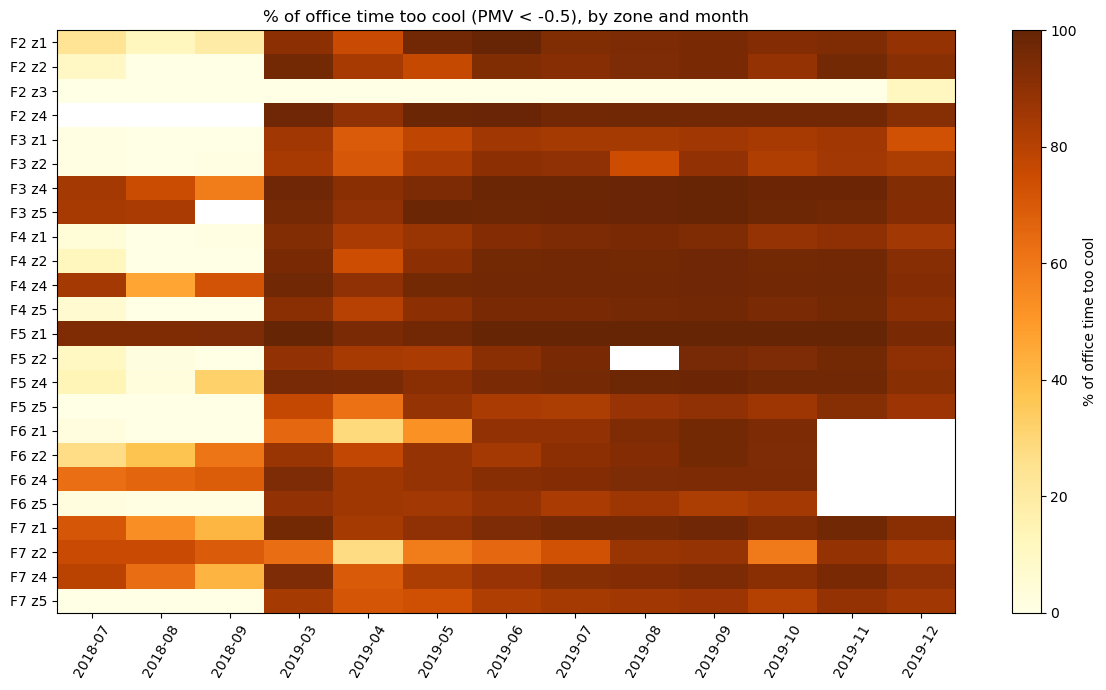

In [7]:
grid = heatmap.assign(row=lambda d: "F" + d["floor"].astype(str) + " " + d["zone"]) \
              .pivot(index="row", columns="month", values="pct_too_cool")
grid = grid.loc[sorted(grid.index, key=lambda r: (int(r.split()[0][1:]), int(r.split()[1][1:])))]

fig, ax = plt.subplots(figsize=(12, 7))
im = ax.imshow(grid.values, aspect="auto", cmap="YlOrBr", vmin=0, vmax=100)
ax.set_xticks(range(grid.shape[1]), grid.columns, rotation=60)
ax.set_yticks(range(grid.shape[0]), grid.index)
ax.set_title("% of office time too cool (PMV < -0.5), by zone and month")
fig.colorbar(im, ax=ax, label="% of office time too cool")
fig.tight_layout()
fig.savefig(COMFORT_DIR / "comfort_heatmap.png", dpi=130)
plt.show()